In [1]:
!pip install --no-index --find-links /kaggle/input/datasets/hinlphmhng/uav-seg-offline-assets/offline_assets/packages segmentation-models-pytorch albumentations omegaconf torchmetrics

Looking in links: /kaggle/input/datasets/hinlphmhng/uav-seg-offline-assets/offline_assets/packages
Processing /kaggle/input/datasets/hinlphmhng/uav-seg-offline-assets/offline_assets/packages/segmentation_models_pytorch-0.5.0-py3-none-any.whl


In [2]:
# ============================================================
# CONFIG — operating-point study (inference only, no training)
# ============================================================
import numpy as np

D = '/kaggle/input/datasets/itmeagain77/op1-dataset'
# best.pth of finished UNet++ seed-123 runs (add their outputs as input datasets). Leave '' to skip a model.
# Old-format checkpoints (plain state_dict, with or without a 'module.' prefix) are accepted too.
CHECKPOINTS = {
    'Exp 1: CE':          f'{D}/R17_unetpp_ce_s2026_best.pth',
    'Exp 2-CED: CE+Dice': f'{D}/R18_unetpp_ced_s2026_best.pth',
    'Exp 3: Uncertainty': f'{D}/R20_unetpp_adaptive_s2026_best.pth',
    'Unified Focal':      '',
    'Exp 2-CEFD: 1:1:1':  f'{D}/R19_unetpp_cefd_s2026_best.pth',
}
REFERENCE = 'Exp 1: CE'      # its validation recall per class is the recall target
FALLBACK_TARGET_RECALL = 0.90 # used when REFERENCE is not given

TARGET_CLASSES = [3, 8, 9, 7]                             # Fallen_trees, Fence, Car, Building
BIAS_GRID = np.round(np.arange(-2.0, 6.0001, 0.25), 2)    # additive bias on the logit of one class
VAL_STRIDE = 1               # use every k-th validation frame (2 halves the validation time)
BATCH_SIZE = 4
NUM_WORKERS = 4
SMOKE = False                # True: 8 validation and 8 test frames, to check the notebook

MODEL_NAME, ENCODER, IMG_SIZE = 'unetpp', 'resnet50', (768, 1280)
print('[CONFIG] models:', [k for k, v in CHECKPOINTS.items() if v], '| grid', BIAS_GRID[0], '...', BIAS_GRID[-1])

[CONFIG] models: ['Exp 1: CE', 'Exp 2-CED: CE+Dice', 'Exp 3: Uncertainty', 'Exp 2-CEFD: 1:1:1'] | grid -2.0 ... 6.0


In [3]:
import os
from pathlib import Path

SUNNY_DIRS = [
    Path('/kaggle/input/datasets/leehien12/uav-forest-sunny-part1'),
    Path('/kaggle/input/datasets/khesng/uav-forest-sunny-next'),
    Path('/kaggle/input/datasets/leehien12/uav-forest-sunny'),
]
OVERCAST_DIRS = [
    Path('/kaggle/input/datasets/hinlphmhng/uav-forest-overcast-1'),
    Path('/kaggle/input/datasets/hinlphmhng/uav-forest-overcast-2'),
]
SPLIT_CONFIG = {
    'train': ['seq1', 'seq3', 'seq4', 'seq5', 'seq8', 'seq9',
              'seq10', 'seq12', 'seq14', 'seq15', 'seq16', 'seq17'],
    'val':   ['seq2', 'seq13', 'seq18'],
    'test':  ['seq6', 'seq7', 'seq11'],
}

def collect_pairs_from_dirs(base_dirs, split_config):
    data = {'train': [], 'val': [], 'test': []}
    found = {}
    for base_path in base_dirs:
        if not Path(base_path).exists():
            print(f'  [WARN] missing: {base_path}')
            continue
        for color_dir in Path(base_path).rglob('color'):
            if not color_dir.is_dir():
                continue
            seq_dir, seq_name = color_dir.parent, color_dir.parent.name
            mask_dir = seq_dir / 'labels'
            if not mask_dir.exists():
                mask_dir = seq_dir / 'label'
            if not mask_dir.exists():
                continue
            target = next((k for k, v in split_config.items() if seq_name in v), None)
            if target is None:
                continue
            n = 0
            for img_p in sorted(list(color_dir.glob('*.png')) + list(color_dir.glob('*.jpg'))):
                mask_p = (mask_dir / img_p.name).with_suffix('.png')
                if not mask_p.exists():
                    mask_p = (mask_dir / img_p.name).with_suffix('.jpg')
                if mask_p.exists():
                    data[target].append((str(img_p), str(mask_p)))
                    n += 1
            found[seq_name] = (target, n)
    return data, found

data, found_seqs = collect_pairs_from_dirs(SUNNY_DIRS + OVERCAST_DIRS, SPLIT_CONFIG)
train_files, val_files, test_files = data['train'], data['val'], data['test']
missing = set(sum(SPLIT_CONFIG.values(), [])) - set(found_seqs)
assert not missing, f'Missing sequences: {sorted(missing)}'
print(f'TRAIN {len(train_files):,} | VAL {len(val_files):,} | TEST {len(test_files):,}')
assert (len(train_files), len(val_files), len(test_files)) == (17454, 4297, 4491), 'Unexpected split sizes'


TRAIN 17,454 | VAL 4,297 | TEST 4,491


In [4]:
import numpy as np
from PIL import Image

LABEL_COLORS = [
    (0, 255, 255), (0, 127, 0), (19, 132, 69), (0, 53, 65), (130, 76, 0),
    (152, 251, 152), (151, 126, 171), (250, 150, 0), (115, 176, 195),
    (123, 123, 123), (0, 0, 0),
]
CLASS_NAMES = ['Sky', 'Deciduous_trees', 'Coniferous_trees', 'Fallen_trees',
               'Dirt_ground', 'Ground_vegetation', 'Rocks', 'Building',
               'Fence', 'Car', 'Empty']
NUM_CLASSES = len(CLASS_NAMES)   # 11, Empty = index 10
EMPTY_CLASS = NUM_CLASSES - 1
PALETTE = np.array(LABEL_COLORS, dtype=np.uint8)

RGB_TO_CLASS_LUT = np.full((256, 256, 256), EMPTY_CLASS, dtype=np.uint8)
for cid, color in enumerate(LABEL_COLORS):
    RGB_TO_CLASS_LUT[color] = cid

def fast_rgb_to_mask(rgb_arr):
    return RGB_TO_CLASS_LUT[rgb_arr[..., 0], rgb_arr[..., 1], rgb_arr[..., 2]]


In [5]:
import torch, json
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import albumentations as A
from albumentations.pytorch import ToTensorV2
import segmentation_models_pytorch as smp
from tqdm import tqdm

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
OUTPUT_DIR = Path('/kaggle/working/outputs') if os.path.exists('/kaggle') else Path('outputs')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

class ForestDataset(Dataset):
    def __init__(self, file_list, transform):
        self.file_list, self.transform = file_list, transform

    def __len__(self):
        return len(self.file_list)

    def __getitem__(self, idx):
        img_path, mask_path = self.file_list[idx]
        img = np.array(Image.open(img_path).convert('RGB'))
        mask = fast_rgb_to_mask(np.array(Image.open(mask_path).convert('RGB')))
        aug = self.transform(image=img, mask=mask)
        return aug['image'], aug['mask'].long()

val_tf = A.Compose([A.Resize(height=IMG_SIZE[0], width=IMG_SIZE[1]),
                    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)), ToTensorV2()])
val_list, test_list = val_files[::VAL_STRIDE], test_files
if SMOKE:
    val_list, test_list = val_list[:8], test_list[:8]
make_loader = lambda files: DataLoader(ForestDataset(files, val_tf), batch_size=BATCH_SIZE, shuffle=False,
                                       num_workers=NUM_WORKERS, pin_memory=True)

def load_model(path):
    ck = torch.load(path, map_location='cpu', weights_only=False)
    sd = ck.get('model_state_dict', ck.get('state_dict', ck)) if isinstance(ck, dict) else ck
    sd = {k[7:] if k.startswith('module.') else k: v for k, v in sd.items()}
    m = smp.UnetPlusPlus(encoder_name=ENCODER, encoder_weights=None, in_channels=3, classes=NUM_CLASSES)
    m.load_state_dict(sd)
    return m.to(DEVICE).eval()

def logits_of(model, imgs):
    with torch.no_grad(), torch.amp.autocast('cuda', dtype=torch.float16, enabled=DEVICE == 'cuda'):
        z = model(imgs.to(DEVICE))
    return z.float().permute(0, 2, 3, 1).reshape(-1, NUM_CLASSES)

def sweep_and_eval(model, loader, bias_vectors=()):
    """(a) per-class sweep: confusion matrix for every (target class, bias) with only that class biased;
       (b) confusion matrix for each full bias vector in bias_vectors. One forward pass per frame."""
    K, G = NUM_CLASSES, len(BIAS_GRID)
    grid = torch.tensor(BIAS_GRID, dtype=torch.float32, device=DEVICE)
    cms = torch.zeros(len(TARGET_CLASSES), G, K * K, dtype=torch.int64, device=DEVICE)
    bvs = [torch.tensor(b, dtype=torch.float32, device=DEVICE) for b in bias_vectors]
    cms_bv = torch.zeros(len(bvs), K * K, dtype=torch.int64, device=DEVICE)
    for imgs, masks in tqdm(loader, leave=False):
        z = logits_of(model, imgs)
        t = masks.to(DEVICE).reshape(-1) * K
        for i, c in enumerate(TARGET_CLASSES):
            other = z.clone(); other[:, c] = -float('inf')
            m_other, a_other = other.max(1)
            margin = z[:, c] - m_other                     # class c wins iff margin + bias > 0
            for j in range(G):
                p = torch.where(margin + grid[j] > 0, c, a_other)
                cms[i, j] += torch.bincount(t + p, minlength=K * K)
        for i, b in enumerate(bvs):
            cms_bv[i] += torch.bincount(t + (z + b).argmax(1), minlength=K * K)
    return (cms.view(len(TARGET_CLASSES), G, K, K).cpu().numpy(),
            cms_bv.view(len(bvs), K, K).cpu().numpy())

def metrics_from_cm(cm):
    """Per-class IoU/recall/precision for the 10 foreground classes; mIoU = their mean (as in the paper)."""
    tp = np.diag(cm).astype(float)
    gt, pred = cm.sum(1).astype(float), cm.sum(0).astype(float)
    iou = np.divide(tp, gt + pred - tp, out=np.zeros_like(tp), where=(gt + pred - tp) > 0)
    rec = np.divide(tp, gt, out=np.zeros_like(tp), where=gt > 0)
    prec = np.divide(tp, pred, out=np.zeros_like(tp), where=pred > 0)
    fg = slice(0, NUM_CLASSES - 1)
    return float(iou[fg].mean()), iou, rec, prec


/usr/local/lib/python3.13/dist-packages/albumentations/check_version.py:147: UserWarning: Error fetching version info <urlopen error [Errno -3] Temporary failure in name resolution>
  data = fetch_version_info()


In [6]:
# ============================================================
# RUN — biases are chosen on the VALIDATION split only, then applied once to the test split
#   rule 'recall': smallest bias whose validation recall reaches the target (REFERENCE recall)
#   rule 'iou'   : bias with the highest validation IoU of that class
# ============================================================
models = {k: v for k, v in CHECKPOINTS.items() if v}
assert models, 'Set at least one path in CHECKPOINTS'
order = ([REFERENCE] if REFERENCE in models else []) + [k for k in models if k != REFERENCE]
target_recall, results = {}, {}

for name in order:
    print(f'\n===== {name} =====')
    model = load_model(models[name])
    val_cms, _ = sweep_and_eval(model, make_loader(val_list))
    zero = int(np.argmin(np.abs(BIAS_GRID)))
    if name == REFERENCE:
        target_recall = {c: metrics_from_cm(val_cms[i, zero])[2][c] for i, c in enumerate(TARGET_CLASSES)}
        print('target recall (validation, reference):', {CLASS_NAMES[c]: round(r, 4) for c, r in target_recall.items()})
    chosen = {'none': np.zeros(NUM_CLASSES), 'recall': np.zeros(NUM_CLASSES), 'iou': np.zeros(NUM_CLASSES)}
    for i, c in enumerate(TARGET_CLASSES):
        rec_v = np.array([metrics_from_cm(val_cms[i, j])[2][c] for j in range(len(BIAS_GRID))])
        iou_v = np.array([metrics_from_cm(val_cms[i, j])[1][c] for j in range(len(BIAS_GRID))])
        goal = target_recall.get(c, FALLBACK_TARGET_RECALL)
        ok = np.where(rec_v >= goal)[0]
        chosen['recall'][c] = BIAS_GRID[ok[0]] if len(ok) else BIAS_GRID[-1]
        chosen['iou'][c] = BIAS_GRID[int(np.argmax(iou_v))]
    print('biases (recall rule):', {CLASS_NAMES[c]: chosen['recall'][c] for c in TARGET_CLASSES})
    print('biases (IoU rule):   ', {CLASS_NAMES[c]: chosen['iou'][c] for c in TARGET_CLASSES})

    test_cms, test_bv = sweep_and_eval(model, make_loader(test_list), [chosen[r] for r in chosen])
    np.savez_compressed(OUTPUT_DIR / f'sweep_{name.split(":")[0].replace(" ", "")}.npz',
                        val=val_cms, test=test_cms, grid=BIAS_GRID, classes=TARGET_CLASSES)
    results[name] = {}
    for (rule, b), cm in zip(chosen.items(), test_bv):
        miou, iou, rec, prec = metrics_from_cm(cm)
        results[name][rule] = {'bias': {CLASS_NAMES[c]: float(b[c]) for c in TARGET_CLASSES}, 'miou': miou,
                               **{CLASS_NAMES[c]: {'iou': iou[c], 'recall': rec[c], 'precision': prec[c]}
                                  for c in TARGET_CLASSES}}
    del model; torch.cuda.empty_cache()

json.dump({'target_recall_val': {CLASS_NAMES[c]: r for c, r in target_recall.items()}, 'results': results},
          open(OUTPUT_DIR / 'operating_point_results.json', 'w'), indent=2, default=float)

print(f"\n{'Model':<22}{'Rule':<8}{'mIoU':>7}" + ''.join(f'{CLASS_NAMES[c][:7]:>22}' for c in TARGET_CLASSES))
print(' ' * 37 + '      IoU / Rec / Prec' * len(TARGET_CLASSES))
for name, rules in results.items():
    for rule, r in rules.items():
        cells = ''.join(f"{100 * r[CLASS_NAMES[c]]['iou']:8.2f}{100 * r[CLASS_NAMES[c]]['recall']:7.2f}"
                        f"{100 * r[CLASS_NAMES[c]]['precision']:7.2f}" for c in TARGET_CLASSES)
        print(f'{name:<22}{rule:<8}{100 * r["miou"]:7.2f}{cells}')
print("\nCheck: the 'none' rows must match the test results already in the paper (differences <0.05 pp).")



===== Exp 1: CE =====


target recall (validation, reference): {'Fallen_trees': np.float64(0.8815), 'Fence': np.float64(0.8498), 'Car': np.float64(0.9489), 'Building': np.float64(0.977)}
biases (recall rule): {'Fallen_trees': np.float64(0.0), 'Fence': np.float64(0.0), 'Car': np.float64(0.0), 'Building': np.float64(0.0)}
biases (IoU rule):    {'Fallen_trees': np.float64(-1.75), 'Fence': np.float64(-1.0), 'Car': np.float64(-1.5), 'Building': np.float64(-2.0)}



===== Exp 2-CED: CE+Dice =====


biases (recall rule): {'Fallen_trees': np.float64(1.75), 'Fence': np.float64(0.25), 'Car': np.float64(1.0), 'Building': np.float64(2.25)}
biases (IoU rule):    {'Fallen_trees': np.float64(-1.25), 'Fence': np.float64(0.0), 'Car': np.float64(-0.75), 'Building': np.float64(-1.0)}



===== Exp 3: Uncertainty =====


biases (recall rule): {'Fallen_trees': np.float64(1.25), 'Fence': np.float64(0.0), 'Car': np.float64(1.25), 'Building': np.float64(2.0)}
biases (IoU rule):    {'Fallen_trees': np.float64(-1.0), 'Fence': np.float64(-0.25), 'Car': np.float64(-0.5), 'Building': np.float64(-0.75)}



===== Exp 2-CEFD: 1:1:1 =====


biases (recall rule): {'Fallen_trees': np.float64(1.0), 'Fence': np.float64(-0.25), 'Car': np.float64(1.5), 'Building': np.float64(1.5)}
biases (IoU rule):    {'Fallen_trees': np.float64(-1.25), 'Fence': np.float64(-0.25), 'Car': np.float64(-0.5), 'Building': np.float64(-1.0)}



Model                 Rule       mIoU               Fallen_                 Fence                   Car               Buildin
                                           IoU / Rec / Prec      IoU / Rec / Prec      IoU / Rec / Prec      IoU / Rec / Prec
Exp 1: CE             none      78.02   54.60  89.73  58.24   54.35  88.86  58.32   77.15  94.64  80.67   85.25  98.18  86.62
Exp 1: CE             recall    78.02   54.60  89.73  58.24   54.35  88.86  58.32   77.15  94.64  80.67   85.25  98.18  86.62
Exp 1: CE             iou       80.45   65.26  78.28  79.69   57.90  86.01  63.92   81.47  91.95  87.73   90.65  95.65  94.54
Exp 2-CED: CE+Dice    none      84.11   68.21  84.62  77.86   72.19  86.71  81.18   88.45  94.10  93.64   93.03  96.95  95.83
Exp 2-CED: CE+Dice    recall    83.34   62.26  89.04  67.43   72.14  86.31  81.46   88.13  94.30  93.09   91.89  98.02  93.62
Exp 2-CED: CE+Dice    iou       84.24   69.49  80.54  83.51   72.05  87.05  80.70   88.50  93.77  94.03   93.13  96.3

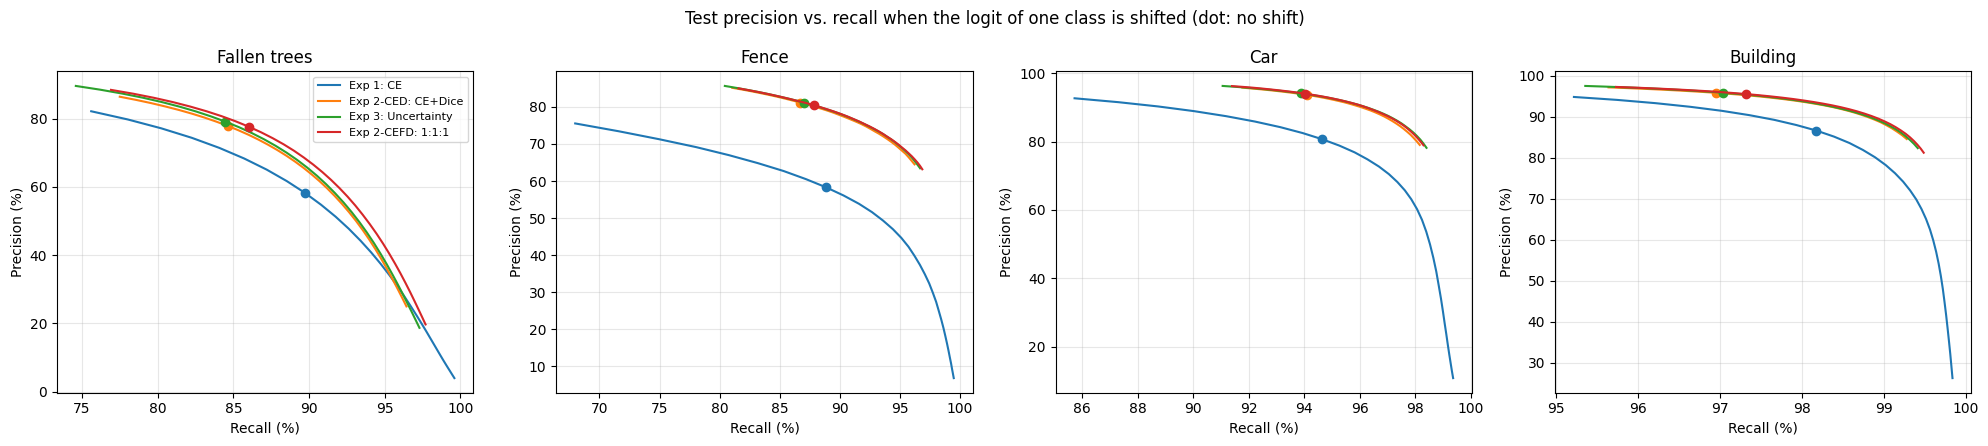

/kaggle/working/OP1_results.zip

In [7]:
# Precision-recall curves on the test split (bias sweep of one class at a time), for the figure.
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, len(TARGET_CLASSES), figsize=(5 * len(TARGET_CLASSES), 4.5))
zero = int(np.argmin(np.abs(BIAS_GRID)))
for name in results:
    d = np.load(OUTPUT_DIR / f'sweep_{name.split(":")[0].replace(" ", "")}.npz')
    for ax, (i, c) in zip(axes, enumerate(TARGET_CLASSES)):
        m = [metrics_from_cm(d['test'][i, j]) for j in range(len(BIAS_GRID))]
        rec, prec = [100 * x[2][c] for x in m], [100 * x[3][c] for x in m]
        line, = ax.plot(rec, prec, label=name)
        ax.plot(rec[zero], prec[zero], 'o', color=line.get_color())
for ax, c in zip(axes, TARGET_CLASSES):
    ax.set_title(CLASS_NAMES[c].replace('_', ' ')); ax.set_xlabel('Recall (%)'); ax.set_ylabel('Precision (%)')
    ax.grid(alpha=0.3)
axes[0].legend(fontsize=8)
fig.suptitle('Test precision vs. recall when the logit of one class is shifted (dot: no shift)')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'fig_operating_point.png', dpi=200, bbox_inches='tight')
plt.show()

import zipfile
zip_path = OUTPUT_DIR.parent / 'OP1_results.zip'
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as z:
    for p in OUTPUT_DIR.glob('*'):
        z.write(p, arcname=p.name)
os.chdir(OUTPUT_DIR.parent)
try:
    from IPython.display import FileLink, display
    display(FileLink(zip_path.name))
except ImportError:
    print(zip_path)
